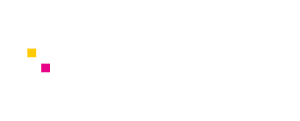

# Pandas Practical Tutorial
**Project:** Computational Biology & Proteomics Foundation (`protein-python-foundations`)  
**Context:** Active Coding During [Pandas Tutorial](https://www.youtube.com/watch?v=VXtjG_GzO7Q)  
**Author:** Afraim Mario  
**Environment:** `bioinfo` (Python 3.11, Pandas 3.0.6)  
**Start Date:** October 28, 2026  
***

## Notebook Navigation & Execution Blueprint
* **Part 1:** Code-Along Sandbox (Series, Dataframes, Importing, Selection, Filtering, Aggreagtion, Data Cleaning)
* **Part 2:** Tiny Tasks Implementation (`task01_load.py` through `task07_merge.py`)
* **Execution Rule:** Pure functions only (`return` instead of `print`), verified via official Pandas docs (`https://pandas.pydata.org/docs/).
***

In [2]:
import pandas as pd
print(pd.__version__)  # making sure of the version

3.0.3


## Series


In [3]:
data = [100, 102, 104]
# labelled indexed one column, metadata = int64
print(pd.Series(data, index=["a", "b", "c"]))
# you can pass index as list, dict, NumPy array or even series

data2 = [100.1, 102.2, 104.3]
print(pd.Series(data2))  # floats

data3 = [True, False, True]
print(pd.Series(data3))  # boolean

data4 = ["A", "B", "C"]
print(pd.Series(data4))  # str

a    100
b    102
c    104
dtype: int64
0    100.1
1    102.2
2    104.3
dtype: float64
0     True
1    False
2     True
dtype: bool
0    A
1    B
2    C
dtype: str


In [4]:
data = [100, 102, 104]
series = pd.Series(data, index=["a", "b", "c"])

print(series.loc["a"])  # location[] acess value
# print(series.loc["d"]) non-existing value error

100


In [5]:
data = [100, 102, 104]
series = pd.Series(data, index=["a", "b", "c"])

series.loc["b"] = 200  # reassigning the index c
print(series)
print(series.iloc[1])  # locating by int location

a    100
b    200
c    104
dtype: int64
200


In [6]:
data = [100, 102, 104, 200, 202]
series = pd.Series(data, index=["a", "b", "c", "d", "e"])

print(series[series >= 200])  # filtering larger than 200
print(series[series < 200])  # filtering smaller than 200

d    200
e    202
dtype: int64
a    100
b    102
c    104
dtype: int64


In [7]:
calories = {"Day 1": 1750, "Day 2": 2100, "Day 3": 1700}
series = pd.Series(calories)  # index are keys
print(series.loc["Day 3"])
series.loc["Day 3"] += 500  # acessing by key and adding 500
print(series)

print(series[series >= 2000])  # filtering based on breaking diet
print(series[series < 2000])  # filtering based on sticking to diet

1700
Day 1    1750
Day 2    2100
Day 3    2200
dtype: int64
Day 2    2100
Day 3    2200
dtype: int64
Day 1    1750
dtype: int64


## DataFrames

In [8]:
data = {"Name": ["Spongebob", "Patrick", "Squidward"],
        "Age": [30, 35, 50]
        }

df = pd.DataFrame(data, index=["Employee 1", "Employee 2", "Employee 3"])
# creating dataframes and indexing
print(df)

print("\nData for Employee 1:\n", df.loc["Employee 1"])
print("\nData for Employee 2:\n", df.iloc[1])

# adding a new column
df["Job"] = ["Cook", "N/A", "Cashier"]
print("\n", df)

# new rows
new_rows = pd.DataFrame(
    [{"Name": "Sandy", "Age": 28, "Job": "Engineer"}, {"Name": "Eugene", "Age": 60, "Job": "Manager"}], index=["Employee 4", "Employee 5"])
df = pd.concat([df, new_rows])  # concatanation
print("\n", df)

                 Name  Age
Employee 1  Spongebob   30
Employee 2    Patrick   35
Employee 3  Squidward   50

Data for Employee 1:
 Name    Spongebob
Age            30
Name: Employee 1, dtype: object

Data for Employee 2:
 Name    Patrick
Age          35
Name: Employee 2, dtype: object

                  Name  Age      Job
Employee 1  Spongebob   30     Cook
Employee 2    Patrick   35      N/A
Employee 3  Squidward   50  Cashier

                  Name  Age       Job
Employee 1  Spongebob   30      Cook
Employee 2    Patrick   35       N/A
Employee 3  Squidward   50   Cashier
Employee 4      Sandy   28  Engineer
Employee 5     Eugene   60   Manager


## Importing

In [9]:
# .csv files, .json files

df = pd.read_csv("data.csv")
print(df)  # first and last 5 rows `truncated data view`
print(df.to_string())  # printing everything a file, CAREFUL!

df1 = pd.read_json("data.json")
print(df1)

      No       Name    Type1   Type2  Height  Weight  Legendary
0      1  Bulbasaur    Grass  Poison     0.7     6.9          0
1      1  Bulbasaur    Grass  Poison     0.7     6.9          0
2      1  Bulbasaur    Grass  Poison     0.7     6.9          0
3      1  Bulbasaur    Grass  Poison     0.7     6.9          0
4      1  Bulbasaur    Grass  Poison     0.7     6.9          0
..   ...        ...      ...     ...     ...     ...        ...
149  146    Moltres     Fire  Flying     2.0    60.0          1
150  147    Dratini   Dragon     NaN     1.8     3.3          0
151  148  Dragonair   Dragon     NaN     4.0    16.5          0
152  149  Dragonite   Dragon  Flying     2.2   210.0          0
153  150     Mewtwo  Psychic     NaN     2.0   122.0          1

[154 rows x 7 columns]
      No        Name     Type1     Type2  Height  Weight  Legendary
0      1   Bulbasaur     Grass    Poison     0.7     6.9          0
1      1   Bulbasaur     Grass    Poison     0.7     6.9          0
2   

## Selection

In [10]:
# slection by column
df = pd.read_csv("data.csv")
# print(df["Name"]) first and last 5 rows `truncated data view`
# selecting multiple columns
print(df[["Name", "Height", "Weight"]].to_string())
# print(df["Name"].to_string()) CAREFUL WITH LARGE DATA!!
# which is actually a 1d series

           Name  Height  Weight
0     Bulbasaur     0.7     6.9
1     Bulbasaur     0.7     6.9
2     Bulbasaur     0.7     6.9
3     Bulbasaur     0.7     6.9
4     Bulbasaur     0.7     6.9
5       Ivysaur     1.0    13.0
6      Venusaur     2.0   100.0
7    Charmander     0.6     8.5
8    Charmeleon     1.1    19.0
9     Charizard     1.7    90.5
10     Squirtle     0.5     9.0
11    Wartortle     1.0    22.5
12    Blastoise     1.6    85.5
13     Caterpie     0.3     2.9
14      Metapod     0.7     9.9
15   Butterfree     1.1    32.0
16       Weedle     0.3     3.2
17       Kakuna     0.6    10.0
18     Beedrill     1.0    29.5
19       Pidgey     0.3     1.8
20    Pidgeotto     1.1    30.0
21      Pidgeot     1.5    39.5
22      Rattata     0.3     3.5
23     Raticate     0.7    18.5
24      Spearow     0.3     2.0
25       Fearow     1.2    38.0
26        Ekans     2.0     6.9
27        Arbok     3.5    65.0
28      Pikachu     0.4     6.0
29       Raichu     0.8    30.0
30    Sa

In [11]:
# slection by row
# setting a specfic col as index
df = pd.read_csv("data.csv", index_col="Name")
# accessing loc property by name index
print(df.loc["Pikachu", ["Height", "Weight"]])
# specfically mentioning in a list what col to print

# selection range from indexes
print("\n", df.loc["Charizard":"Blastoise", ["Height", "Weight"]])
# selection range from int indexes `end exclusive`
print("\n", df.iloc[0:11:2, 0:3])
# every step of 2, range int of index for col

Height    0.4
Weight    6.0
Name: Pikachu, dtype: float64

            Height  Weight
Name                     
Charizard     1.7    90.5
Squirtle      0.5     9.0
Wartortle     1.0    22.5
Blastoise     1.6    85.5

             No  Type1   Type2
Name                         
Bulbasaur    1  Grass  Poison
Bulbasaur    1  Grass  Poison
Bulbasaur    1  Grass  Poison
Venusaur     3  Grass  Poison
Charmeleon   5   Fire     NaN
Squirtle     7  Water     NaN


In [12]:
# slection by row
df = pd.read_csv("data.csv", index_col="Name")

pokemon = input("Enter a pokemon name:")
try:
    print(df.loc[pokemon])
except KeyError:
    print(f"{pokemon} is not found!")

No                 25
Type1        Electric
Type2             NaN
Height            0.4
Weight            6.0
Legendary           0
Name: Pikachu, dtype: object


## Filtering

In [13]:
# keeping rows that match a condition
df = pd.read_csv("data.csv")
tall = df[df["Height"] >= 5]
heavy = df[df["Weight"] > 230]
legendary = df[df["Legendary"] == 1]  # True = 1
water_pok = df[(df["Type1"] == "Water") | (df["Type2"] == "Water")]
fire_flying = df[(df["Type1"] == "Fire") & (df["Type2"] == "Flying")]

print("tall pokemons\n", tall)
print("\nheavy pokemons\n", heavy)
print("\nlegendary pokemons\n", legendary)
print("\nwater_pokemons 1st or 2nd type\n", water_pok)
print("\nfire flying pokemons\n", fire_flying)

tall pokemons
       No      Name  Type1   Type2  Height  Weight  Legendary
98    95      Onix   Rock  Ground     8.8   210.0          0
133  130  Gyarados  Water  Flying     6.5   235.0          0

heavy pokemons
       No      Name   Type1   Type2  Height  Weight  Legendary
79    76     Golem    Rock  Ground     1.4   300.0          0
133  130  Gyarados   Water  Flying     6.5   235.0          0
146  143   Snorlax  Normal     NaN     2.1   460.0          0

legendary pokemons
       No      Name     Type1   Type2  Height  Weight  Legendary
147  144  Articuno       Ice  Flying     1.7    55.4          1
148  145    Zapdos  Electric  Flying     1.6    52.6          1
149  146   Moltres      Fire  Flying     2.0    60.0          1
153  150    Mewtwo   Psychic     NaN     2.0   122.0          1

water_pokemons 1st or 2nd type
       No        Name  Type1     Type2  Height  Weight  Legendary
10     7    Squirtle  Water       NaN     0.5     9.0          0
11     8   Wartortle  Water      

## Aggregate Functions

In [14]:
df = pd.read_csv("data.csv")

print("Mean:\n", df.mean(numeric_only=True))  # no mean on str columns
# find the mean for any numeric col

# Whole dataframe aggregate functions
print("\nMean:\n", df.sum(numeric_only=True))  # sum of all numeric col
print("\nMinimum:\n", df.min(numeric_only=True))  # min of any numeric col
print("\nMaxiumum:\n", df.max(numeric_only=True))  # max for any numeric col
print("\nCounts:\n", df.count(numeric_only=rue))  # max for any numeric col

Mean:
 No           73.564935
Height        1.187013
Weight       45.209740
Legendary     0.025974
dtype: float64

Mean:
 No           11329.0
Height         182.8
Weight        6962.3
Legendary        4.0
dtype: float64

Minimum:
 No           1.0
Height       0.2
Weight       0.1
Legendary    0.0
dtype: float64

Maxiumum:
 No           150.0
Height         8.8
Weight       460.0
Legendary      1.0
dtype: float64


NameError: name 'rue' is not defined

In [ ]:
df = pd.read_csv("data.csv")

print("Mean:\n", df["Height"].mean())  # no mean on str columns
# find the mean for any numeric col

# Single aggregate functions using subscript operator
print("\nMean:\n", df["Height"].sum())  # sum of all numeric col
print("\nMinimum:\n", df["Height"].min())  # min of any numeric col
print("\nMaxiumum:\n", df["Height"].max())  # max for any numeric col
print("\nCounts:\n", df["Height"].count())  # max for any numeric col

Mean:
 1.2

Mean:
 180.0

Minimum:
 0.2

Maxiumum:
 8.8

Counts:
 150
Type1
Bug         0.900000
Dragon      2.666667
Electric    0.855556
Fairy       0.950000
Fighting    1.185714
Fire        1.216667
Ghost       1.466667
Grass       1.083333
Ground      0.850000
Ice         1.550000
Normal      0.986364
Poison      1.221429
Psychic     1.371429
Rock        1.844444
Water       1.300000
Name: Height, dtype: float64


In [ ]:
df = pd.read_csv("data.csv")

group = df.groupby("Type1")
print(group)  # proting object location in memory
# grouped by each Type1 and applying mean on them
print(group["Height"].mean())
print(group["Height"].min())
print(group["Height"].max())
print(group["Height"].count())

Type1
Bug         0.900000
Dragon      2.666667
Electric    0.855556
Fairy       0.950000
Fighting    1.185714
Fire        1.216667
Ghost       1.466667
Grass       1.083333
Ground      0.850000
Ice         1.550000
Normal      0.986364
Poison      1.221429
Psychic     1.371429
Rock        1.844444
Water       1.300000
Name: Height, dtype: float64
Type1
Bug         0.3
Dragon      1.8
Electric    0.3
Fairy       0.6
Fighting    0.5
Fire        0.6
Ghost       1.3
Grass       0.4
Ground      0.2
Ice         1.4
Normal      0.3
Poison      0.4
Psychic     0.9
Rock        0.4
Water       0.3
Name: Height, dtype: float64
Type1
Bug         1.5
Dragon      4.0
Electric    1.6
Fairy       1.3
Fighting    1.6
Fire        2.0
Ghost       1.6
Grass       2.0
Ground      1.9
Ice         1.7
Normal      2.2
Poison      3.5
Psychic     2.0
Rock        8.8
Water       6.5
Name: Height, dtype: float64
Type1
Bug         12
Dragon       3
Electric     9
Fairy        2
Fighting     7
Fire        12
Ghos

## Data Cleaning

In [ ]:
df = pd.read_csv("data.csv")

df = df.drop(columns=["Legendary"])  # dropping, exclusion of irrelvant col
df = df.dropna(subset=["Type2"])  # removing Not avaliable `no values rows`
print(df.to_string())

      No        Name     Type1     Type2  Height  Weight
0      1   Bulbasaur     Grass    Poison     0.7     6.9
1      2     Ivysaur     Grass    Poison     1.0    13.0
2      3    Venusaur     Grass    Poison     2.0   100.0
5      6   Charizard      Fire    Flying     1.7    90.5
11    12  Butterfree       Bug    Flying     1.1    32.0
12    13      Weedle       Bug    Poison     0.3     3.2
13    14      Kakuna       Bug    Poison     0.6    10.0
14    15    Beedrill       Bug    Poison     1.0    29.5
15    16      Pidgey    Normal    Flying     0.3     1.8
16    17   Pidgeotto    Normal    Flying     1.1    30.0
17    18     Pidgeot    Normal    Flying     1.5    39.5
20    21     Spearow    Normal    Flying     0.3     2.0
21    22      Fearow    Normal    Flying     1.2    38.0
30    31   Nidoqueen    Poison    Ground     1.3    60.0
33    34    Nidoking    Poison    Ground     1.4    62.0
38    39  Jigglypuff    Normal     Fairy     0.5     5.5
39    40  Wigglytuff    Normal 

In [ ]:
df = pd.read_csv("data.csv")

df = df.fillna({"Type2": "None"})  # replacing missing vlaues `Nan` to None
df["Type1"] = df["Type1"].replace(
    {"Grass": "GRASS", "Water": "WATER", "Fire": "FIRE"})
# replacing specfic isntances

df["Name"] = df["Name"].str.lower()  # lowering casing all names rows

df["Legendary"] = df["Legendary"].astype(bool)  # replacing 01 dtype to boolean

df = df.drop_duplicates()  # removing data

print(df.to_string())

      No        Name     Type1     Type2  Height  Weight  Legendary
0      1   bulbasaur     GRASS    Poison     0.7     6.9      False
5      2     ivysaur     GRASS    Poison     1.0    13.0      False
6      3    venusaur     GRASS    Poison     2.0   100.0      False
7      4  charmander      FIRE      None     0.6     8.5      False
8      5  charmeleon      FIRE      None     1.1    19.0      False
9      6   charizard      FIRE    Flying     1.7    90.5      False
10     7    squirtle     WATER      None     0.5     9.0      False
11     8   wartortle     WATER      None     1.0    22.5      False
12     9   blastoise     WATER      None     1.6    85.5      False
13    10    caterpie       Bug      None     0.3     2.9      False
14    11     metapod       Bug      None     0.7     9.9      False
15    12  butterfree       Bug    Flying     1.1    32.0      False
16    13      weedle       Bug    Poison     0.3     3.2      False
17    14      kakuna       Bug    Poison     0.6